# 让小车学会保持平衡

WalkingLab × Hands-On Modern RL 配套实验。

观察奖励曲线，再播放这个模型自己学到的策略。

- 运行资源：CPU
- 默认快速预算：30,000 个训练单位；具体单位由任务决定。
- 完整预算建议：30,000 个环境步；实际耗时取决于实例性能。
- [在线 Studio](https://modelscope.cn/studios/walkinglab/hands-on-modern-rl-experiment01-cartpole)
- [实验源码](https://github.com/walkinglabs/hands-on-modern-rl/tree/main/code/chapter01_cartpole)
- [配套章节](https://walkinglabs.github.io/hands-on-modern-rl/chapter01_cartpole/training)

Notebook 导入 Studio 使用的同一套训练实现。按顺序运行，比较检查点曲线和最终策略回放。
首次安装需要下载原生环境或模拟器资源；后续运行会复用工作目录缓存。


## 1. 实验目标与训练安排

我们观察训练预算增加后，策略在任务评估指标上的变化。先用快速预算检查环境和日志，
确认结果单元格能产生曲线或结果文件，再延长训练。

使用普通 CPU Notebook 实例即可。

观察各轮检查点的评估曲线与策略回放，再增加训练步数进行对照。


## 2. 安装配套 Studio 运行环境

安装当前实验所需的依赖，并加载与 Studio 相同的训练代码。


In [1]:
from __future__ import annotations

import hashlib
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

REPOSITORY_URL = "https://github.com/walkinglabs/hands-on-modern-rl.git"
SPACE_SLUG = "hands-on-modern-rl-experiment01-cartpole"
INSTALL_DEPENDENCIES = os.getenv("HANDS_ON_LAB_PREINSTALLED") != "1"

def locate_or_clone_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "modelscope-space" / SPACE_SLUG).is_dir():
            return candidate
    workspace = Path("/mnt/workspace") if Path("/mnt/workspace").is_dir() else Path.cwd()
    target = workspace / "hands-on-modern-rl-notebooks" / "source"
    target.parent.mkdir(parents=True, exist_ok=True)
    if (target / ".git").is_dir():
        subprocess.run(["git", "-C", str(target), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL, str(target)], check=True)
    return target

REPO_ROOT = locate_or_clone_repo()
SPACE_DIR = REPO_ROOT / "modelscope-space" / SPACE_SLUG
requirements = SPACE_DIR / "requirements.txt"
packages = SPACE_DIR / "packages.txt"
cache_root = Path("/mnt/workspace/hands-on-modern-rl-notebooks") if Path("/mnt/workspace").is_dir() else REPO_ROOT / ".cache" / "online-experiments"
cache_root.mkdir(parents=True, exist_ok=True)
digest = hashlib.sha256(requirements.read_bytes() + (packages.read_bytes() if packages.exists() else b"")).hexdigest()[:12]
marker = cache_root / f"{SPACE_SLUG}-{digest}.ready"

if INSTALL_DEPENDENCIES and not marker.exists():
    if packages.exists() and sys.platform.startswith("linux") and hasattr(os, "geteuid") and os.geteuid() == 0:
        system_packages = [line.strip() for line in packages.read_text().splitlines() if line.strip() and not line.startswith("#")]
        subprocess.run(["apt-get", "update"], check=True)
        subprocess.run(["apt-get", "install", "-y", "--no-install-recommends", *system_packages], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "-r", str(requirements)], check=True)
    marker.touch()
else:
    print(f"Dependency cache ready: {marker}")

if importlib.util.find_spec("ipywidgets") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "ipywidgets>=8,<9"],
        check=True,
    )

os.chdir(SPACE_DIR)
if str(SPACE_DIR) not in sys.path:
    sys.path.insert(0, str(SPACE_DIR))
print(f"代码仓库： {REPO_ROOT}")
print(f"实验运行目录： {SPACE_DIR}")


Dependency cache ready: /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-zh/workspaces/cartpole/.cache/online-experiments/hands-on-modern-rl-experiment01-cartpole-1e241ccbaa8e.ready
代码仓库： /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-zh/workspaces/cartpole
实验运行目录： /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-zh/workspaces/cartpole/modelscope-space/hands-on-modern-rl-experiment01-cartpole


## 3. 设置训练轮次

选择任务、每轮步数和总轮次。每一轮都保留独立的模型与评估结果。


In [2]:
import importlib

if SPACE_SLUG.endswith("experiment10-minestudio"):
    subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--no-deps", "minestudio==1.1.6"], check=True)
if SPACE_SLUG.endswith("experiment11-unity-mlagents"):
    from bootstrap_mlagents import ensure_mlagents
    ensure_mlagents()

runtime = importlib.import_module("space_runtime")
tasks = {item["key"]: item for item in runtime.TASKS}
print("可选任务：")
for key, item in tasks.items():
    title = item.get("title", {})
    print(f"  {key:20s} {title.get('zh', title)} · {item.get('environment', 'environment provided by runtime')}")

TASK_KEY = "cartpole-ppo"
STEPS_PER_EPOCH = 15000
EPOCHS = 2
TRAINING_BUDGET = STEPS_PER_EPOCH * EPOCHS
LEARNING_RATE = 3e-4
GAMMA = 0.99
EPSILON = 0.10
SEED = 42

if TASK_KEY not in tasks:
    raise ValueError(f"未知任务 TASK_KEY={TASK_KEY!r}，请选择以下任务之一：{list(tasks)}")
selected_task = tasks[TASK_KEY]
print("\n所选任务：", selected_task.get("title", {}).get("zh", TASK_KEY))
print("算法：", selected_task.get("algorithm"))
print(f"轮次安排：{EPOCHS} 轮 × {STEPS_PER_EPOCH:,} 步 = {TRAINING_BUDGET:,} 总步数")
print("每轮都会评估并保存一个可单独选择的模型。")


objc[28243]: Class SDLApplication is implemented in both /Users/sanbu/Documents/Codex/2026-10-20/revie/work/studio-venv/lib/python3.12/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x11dd94890) and /Users/sanbu/Documents/Codex/2026-10-20/revie/work/studio-venv/lib/python3.12/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11f6012c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[28243]: Class SDLAppDelegate is implemented in both /Users/sanbu/Documents/Codex/2026-10-20/revie/work/studio-venv/lib/python3.12/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x11dd948e0) and /Users/sanbu/Documents/Codex/2026-10-20/revie/work/studio-venv/lib/python3.12/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11f601318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[28243]: Class SDLTranslatorResponder is implemented in both /Users/sanbu/Documents/

可选任务：
  cartpole-ppo         CartPole-v1 · PPO · CartPole-v1

所选任务： CartPole-v1 · PPO
算法： PPO
轮次安排：2 轮 × 15,000 步 = 30,000 总步数
每轮都会评估并保存一个可单独选择的模型。


## 4. 训练并保存每轮模型

观察实际训练日志，等待模型索引、评估结果和结果文件写入工作目录。


In [3]:
from IPython.display import display
import json
import matplotlib.pyplot as plt
import time

print('Device: CPU')

print("启动与在线 Studio 相同的训练流程…\n")
events = []
epoch_models = []
MODEL_INDEX = SPACE_DIR / "artifacts" / "notebook-models.json"
MODEL_INDEX.parent.mkdir(parents=True, exist_ok=True)

def persist_epoch_models():
    try:
        saved_index = json.loads(MODEL_INDEX.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError, OSError):
        saved_index = {"models": []}
    previous = [item for item in saved_index.get("models", []) if isinstance(item, dict)]
    new_ids = {item["model_id"] for item in epoch_models}
    merged = epoch_models + [item for item in previous if item.get("model_id") not in new_ids]
    MODEL_INDEX.write_text(json.dumps({"models": merged}, indent=2, ensure_ascii=False), encoding="utf-8")

for event in runtime.run(TASK_KEY, TRAINING_BUDGET, LEARNING_RATE, GAMMA, EPSILON, SEED, checkpoints=EPOCHS):
    events.append(dict(event))
    if event.get("model") and event.get("checkpoint_index"):
        model_path = str(event["model"])
        model_file = Path(model_path)
        try:
            relative_model_id = model_file.relative_to(SPACE_DIR / "artifacts").as_posix()
        except ValueError:
            relative_model_id = model_file.name
        epoch_models.append({
            "model_id": str(event.get("model_id") or relative_model_id),
            "task_key": TASK_KEY,
            "epoch": int(event["checkpoint_index"]),
            "epochs": int(event.get("checkpoint_count") or EPOCHS),
            "step": int(event.get("step") or 0),
            "score": event.get("score"),
            "model": model_path,
            "preview": str(event.get("preview") or ""),
            "created_ns": time.time_ns(),
        })
        persist_epoch_models()
    message = event.get("log") or event.get("detail")
    if message:
        print(message, flush=True)

if not events:
    raise RuntimeError("训练没有返回任何事件，请检查前面的日志。")
final_event = events[-1]
print("\n最终阶段：", final_event.get("phase", "complete"))
print("最终得分：", final_event.get("score", "见训练日志"))
print(f"已保存 {len(epoch_models)} 个本次运行可选择的轮次模型。")
print("模型索引：", MODEL_INDEX)


Device: CPU
启动与在线 Studio 相同的训练流程…



PPO initialized · n_steps=1000 batch_size=50 initial_reward=85.6


EPOCH 1/2 step=15,000 mean_reward=469.4 std=61.2
SAVE model=policy.zip replay_reward=369


EPOCH 2/2 step=30,000 mean_reward=500.0 std=0.0
SAVE model=policy.zip replay_reward=500


Saved 2 independently selectable PPO policies · final_mean=500.0



最终阶段： complete
最终得分： 500.0
已保存 2 个本次运行可选择的轮次模型。
模型索引： /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-zh/workspaces/cartpole/modelscope-space/hands-on-modern-rl-experiment01-cartpole/artifacts/notebook-models.json


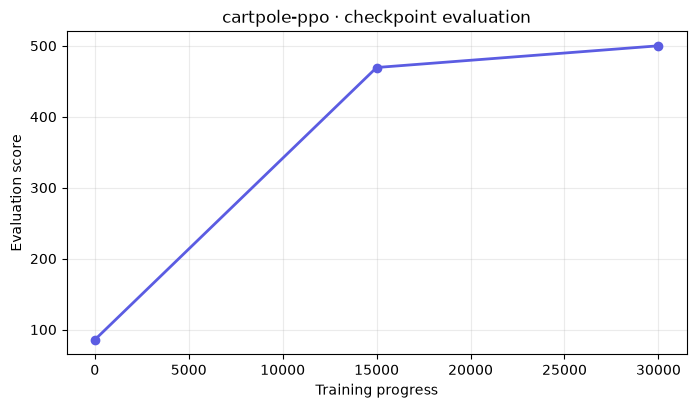

运行下面的推理单元格，选择轮次模型并查看该策略的回放。


In [4]:
x = final_event.get("x", [])
y = final_event.get("y", [])
if x and y:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(x, y, marker="o", color="#5b5ce2", linewidth=2)
    ax.set_title(f"{TASK_KEY} · checkpoint evaluation")
    ax.set_xlabel("Training progress")
    ax.set_ylabel("Evaluation score")
    ax.grid(alpha=0.25)
    plt.show()
else:
    print("此任务通过结果文件展示实验结果。")

print("运行下面的推理单元格，选择轮次模型并查看该策略的回放。")


## 5. 加载已保存模型并回放

选择器重新读取磁盘中的模型索引。只要 Notebook 工作目录仍保留，内核重启后也能重新加载。
Studio 与 Notebook 使用独立容器，因此这里列出当前 Notebook 工作目录产生的模型。
选择一个轮次，再点击“回放所选策略”，检查该模型的实际行为。


In [5]:
import json
from pathlib import Path
from IPython.display import Image as NotebookImage, clear_output, display
import ipywidgets as widgets

MODEL_INDEX = SPACE_DIR / "artifacts" / "notebook-models.json"

def load_notebook_models():
    try:
        payload = json.loads(MODEL_INDEX.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError, OSError):
        return []
    records = [
        item for item in payload.get("models", [])
        if isinstance(item, dict) and item.get("model_id") and item.get("task_key") == TASK_KEY
    ]
    return sorted(
        records,
        key=lambda item: (
            int(item.get("created_ns", 0)),
            int(item.get("step", 0)),
            int(item.get("epoch", 0)),
        ),
        reverse=True,
    )

trained_models = load_notebook_models()
if not trained_models:
    raise RuntimeError("未找到已保存的轮次模型，请先运行上面的训练单元格。")

def model_label(record):
    score = record.get("score")
    score_text = "—" if score is None else f"{float(score):.2f}"
    return (
        f"轮次 {record.get('epoch')}/{record.get('epochs')} · "
        f"{int(record.get('step', 0)):,} 步 · 得分 {score_text} · {record['model_id']}"
    )

model_by_id = {record["model_id"]: record for record in trained_models}
model_picker = widgets.Dropdown(
    options=[(model_label(record), record["model_id"]) for record in trained_models],
    value=trained_models[0]["model_id"],
    description="训练轮次模型：",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "110px"},
)
visualize_button = widgets.Button(
    description="回放所选策略",
    button_style="primary",
    icon="play",
    layout=widgets.Layout(width="240px"),
)
inference_output = widgets.Output()

def visualize_selected(_=None):
    record = model_by_id[model_picker.value]
    with inference_output:
        clear_output(wait=True)
        print("加载已保存模型：", record["model"])
        preview = record.get("preview")

        if hasattr(runtime, "render_preview"):
            try:
                rendered = runtime.render_preview(record["model_id"])
                preview = rendered.get("preview", preview)
                print("已生成新的确定性策略回放。")
            except Exception as exc:
                print(f"新的回放暂不可用（{type(exc).__name__}），显示此轮已保存的回放。")
        elif hasattr(runtime, "render_saved_model"):
            try:
                rendered = runtime.render_saved_model(TASK_KEY, record["model"], record["model_id"])
                preview = rendered.get("preview", preview)
                print("已从所选模型生成新的策略回放。")
            except Exception as exc:
                print(f"新的回放暂不可用（{type(exc).__name__}），显示此轮已保存的回放。")

        preview_path = Path(str(preview)) if preview else None
        if preview_path and preview_path.is_file():
            display(NotebookImage(filename=str(preview_path)))
        else:
            print("此检查点没有可用的回放文件。")
        print("模型：", record["model"])
        print("轮次：", f"{record.get('epoch')}/{record.get('epochs')}")
        print("训练步数：", f"{int(record.get('step', 0)):,}")
        print("评估得分：", record.get("score", "—"))

visualize_button.on_click(visualize_selected)
display(widgets.VBox([model_picker, visualize_button, inference_output]))
print("默认选择最新轮次；也可以选择其他已保存模型，然后点击 回放所选策略.")


默认选择最新轮次；也可以选择其他已保存模型，然后点击 回放所选策略.


## 6. 先检查结果，再延长预算

比较第一个和最后一个检查点，再观察策略回放。曲线上升而回放行为异常时，
需要检查奖励、评估方式和渲染是否对应同一策略。快速预算下的平坦曲线也不足以下结论。

延长训练可参考：30,000 个环境步；实际耗时取决于实例性能。比较方法时固定预算，并至少检查三个随机种子的结果。


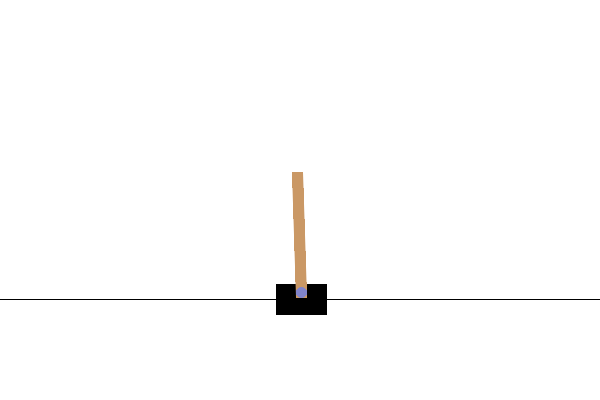

{
  "score": 500.0,
  "steps": 30000,
  "epochs": 2,
  "checkpoints": 2,
  "preview": "learned-policy.gif"
}


In [6]:
import json
from IPython.display import Image as NotebookImage, display

records = epoch_models if "epoch_models" in globals() else trained_models
assert records, "Training must produce a saved checkpoint"
latest = max(records, key=lambda record: (record.get("created_ns", 0), record.get("step", 0)))
preview = Path(str(latest.get("preview", "")))
assert preview.is_file(), "Training must produce a replay or result image"
display(NotebookImage(filename=str(preview)))
output_id = os.getenv("HANDS_ON_LAB_ID", SPACE_SLUG)
output = Path(os.getenv("HANDS_ON_LAB_OUTPUT", str(cache_root / "results"))) / output_id
output.mkdir(parents=True, exist_ok=True)
metrics = {"score": latest.get("score"), "steps": latest.get("step"),
           "epochs": EPOCHS, "checkpoints": len(records), "preview": preview.name}
(output / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))


## 本次运行结果

CPU · Python 3.12.13 · 17.19 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/cartpole-zh.html)
